<a href="https://colab.research.google.com/github/wulanrdy-web/Tugas-Games-2D/blob/main/Tugas_Games_2D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Algoritma   Biaya     Node      Waktu (ms)  
-------------------------------------------------------
Dijkstra    38        190       1.171       
A*          38        158       0.936       


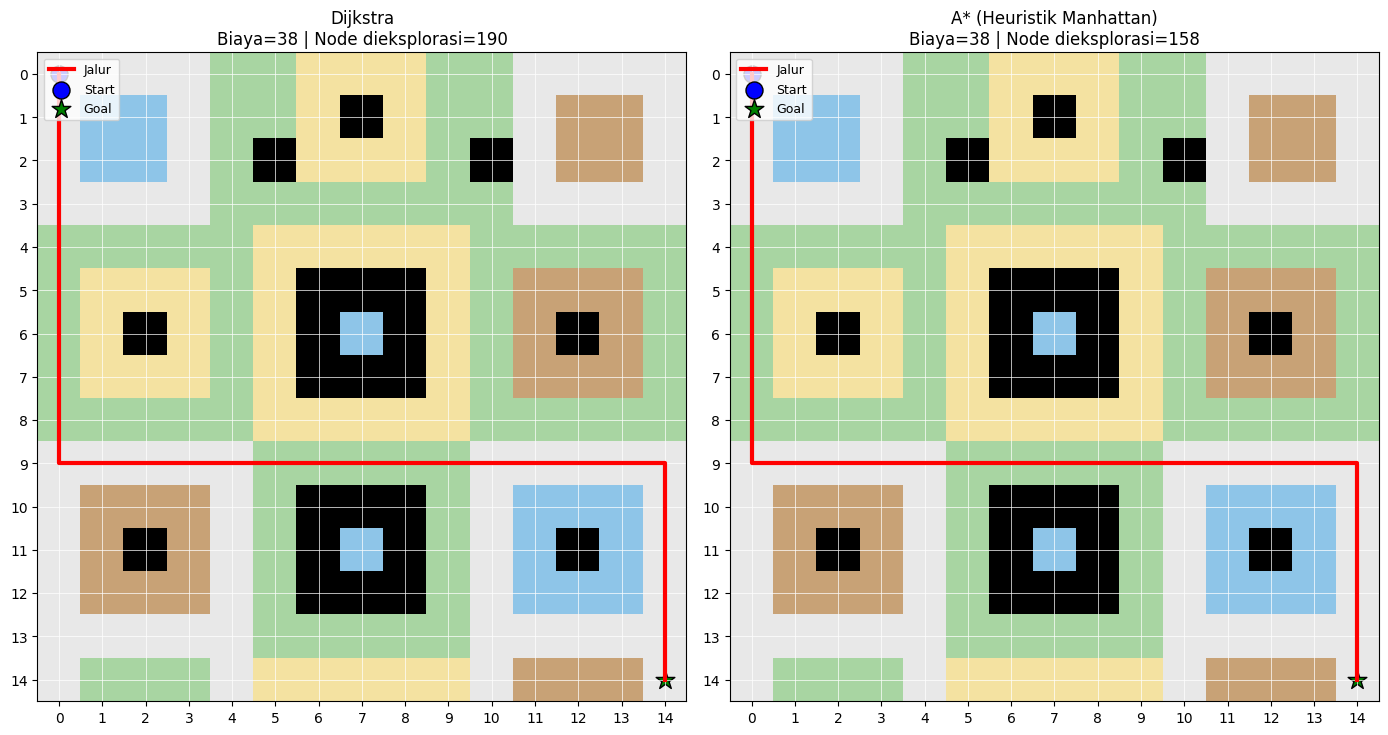

In [1]:
# ============================================================
# SISTEM PATHFINDING 2D: DIJKSTRA vs A*
# ============================================================
import heapq
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import time

# ------------------------------------------------------------
# 1. DEFINISI MEDAN & BOBOT
# ------------------------------------------------------------
# 0 = tanah biasa (bobot 1)
# 1 = rumput      (bobot 2)
# 2 = pasir       (bobot 3)
# 3 = lumpur      (bobot 5)
# 4 = air         (bobot 8)
# 9 = rintangan (tidak bisa dilewati)

TERRAIN_COST = {0: 1, 1: 2, 2: 3, 3: 5, 4: 8}
OBSTACLE = 9

# Peta 15 x 15
grid = np.array([
    [0,0,0,0,1,1,2,2,2,1,1,0,0,0,0],
    [0,4,4,0,1,1,2,9,2,1,1,0,3,3,0],
    [0,4,4,0,1,9,2,2,2,1,9,0,3,3,0],
    [0,0,0,0,1,1,1,1,1,1,1,0,0,0,0],
    [1,1,1,1,1,2,2,2,2,2,1,1,1,1,1],
    [1,2,2,2,1,2,9,9,9,2,1,3,3,3,1],
    [1,2,9,2,1,2,9,4,9,2,1,3,9,3,1],
    [1,2,2,2,1,2,9,9,9,2,1,3,3,3,1],
    [1,1,1,1,1,2,2,2,2,2,1,1,1,1,1],
    [0,0,0,0,0,1,1,1,1,1,0,0,0,0,0],
    [0,3,3,3,0,1,9,9,9,1,0,4,4,4,0],
    [0,3,9,3,0,1,9,4,9,1,0,4,9,4,0],
    [0,3,3,3,0,1,9,9,9,1,0,4,4,4,0],
    [0,0,0,0,0,1,1,1,1,1,0,0,0,0,0],
    [0,1,1,1,0,2,2,2,2,2,0,3,3,3,0],
])

START = (0, 0)
GOAL  = (14, 14)

# ------------------------------------------------------------
# 2. FUNGSI BANTU
# ------------------------------------------------------------
def neighbors(node):
    """4-arah (atas, bawah, kiri, kanan)."""
    r, c = node
    for dr, dc in [(-1,0),(1,0),(0,-1),(0,1)]:
        nr, nc = r+dr, c+dc
        if 0 <= nr < grid.shape[0] and 0 <= nc < grid.shape[1]:
            yield (nr, nc)

def move_cost(a, b):
    """Biaya pindah dari a ke b (berdasarkan bobot medan tujuan)."""
    if grid[b] == OBSTACLE:
        return None
    return TERRAIN_COST[grid[b]]

def heuristic(a, b):
    """Heuristik Manhattan (admissible untuk 4-arah)."""
    return abs(a[0]-b[0]) + abs(a[1]-b[1])

def reconstruct(came_from, current):
    path = [current]
    while current in came_from:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path

# ------------------------------------------------------------
# 3. ALGORITMA DIJKSTRA
# ------------------------------------------------------------
def dijkstra(start, goal):
    frontier = [(0, start)]
    came_from = {}
    cost_so_far = {start: 0}
    explored = 0

    while frontier:
        cost, current = heapq.heappop(frontier)
        explored += 1

        if current == goal:
            return reconstruct(came_from, current), cost, explored

        for nxt in neighbors(current):
            step = move_cost(current, nxt)
            if step is None:
                continue
            new_cost = cost_so_far[current] + step
            if nxt not in cost_so_far or new_cost < cost_so_far[nxt]:
                cost_so_far[nxt] = new_cost
                came_from[nxt] = current
                heapq.heappush(frontier, (new_cost, nxt))
    return None, None, explored

# ------------------------------------------------------------
# 4. ALGORITMA A*
# ------------------------------------------------------------
def astar(start, goal):
    frontier = [(heuristic(start, goal), 0, start)]
    came_from = {}
    g_score = {start: 0}
    explored = 0

    while frontier:
        f, g, current = heapq.heappop(frontier)
        explored += 1

        if current == goal:
            return reconstruct(came_from, current), g, explored

        for nxt in neighbors(current):
            step = move_cost(current, nxt)
            if step is None:
                continue
            tentative_g = g_score[current] + step
            if nxt not in g_score or tentative_g < g_score[nxt]:
                g_score[nxt] = tentative_g
                came_from[nxt] = current
                f_new = tentative_g + heuristic(nxt, goal)
                heapq.heappush(frontier, (f_new, tentative_g, nxt))
    return None, None, explored

# ------------------------------------------------------------
# 5. VISUALISASI
# ------------------------------------------------------------
def visualize(paths_info):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    colors = ['#e8e8e8', '#a8d5a2', '#f4e2a1', '#c8a276', '#8ec5e8', '#000000']
    cmap = ListedColormap(colors)

    for ax, (title, path, cost, explored) in zip(axes, paths_info):
        ax.imshow(grid, cmap=cmap, vmin=0, vmax=5)
        if path:
            ys = [p[0] for p in path]
            xs = [p[1] for p in path]
            ax.plot(xs, ys, color='red', linewidth=3, label='Jalur')
        ax.scatter(START[1], START[0], c='blue', s=150,
                   marker='o', edgecolors='k', label='Start')
        ax.scatter(GOAL[1], GOAL[0], c='green', s=200,
                   marker='*', edgecolors='k', label='Goal')
        ax.set_title(f"{title}\nBiaya={cost} | Node dieksplorasi={explored}",
                     fontsize=12)
        ax.set_xticks(range(15)); ax.set_yticks(range(15))
        ax.grid(color='white', linewidth=0.5)
        ax.legend(loc='upper left', fontsize=9)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. JALANKAN & BANDINGKAN
# ------------------------------------------------------------
t0 = time.perf_counter()
path_d, cost_d, exp_d = dijkstra(START, GOAL)
t1 = time.perf_counter()
time_d = (t1 - t0) * 1000

t0 = time.perf_counter()
path_a, cost_a, exp_a = astar(START, GOAL)
t1 = time.perf_counter()
time_a = (t1 - t0) * 1000

print("=" * 55)
print(f"{'Algoritma':<12}{'Biaya':<10}{'Node':<10}{'Waktu (ms)':<12}")
print("-" * 55)
print(f"{'Dijkstra':<12}{cost_d:<10}{exp_d:<10}{time_d:<12.3f}")
print(f"{'A*':<12}{cost_a:<10}{exp_a:<10}{time_a:<12.3f}")
print("=" * 55)

visualize([
    ("Dijkstra", path_d, cost_d, exp_d),
    ("A* (Heuristik Manhattan)", path_a, cost_a, exp_a),
])